# Daily, Monthly and Annual Precipitation from GPM IMERG (Virginia)

This notebook aggregates half-hourly **GPM IMERG** satellite precipitation (`NASA/GPM_L3/IMERG_V07`, 0.1°)
to daily, monthly and annual totals over Virginia in Google Earth Engine, and exports annual precipitation maps as GeoTIFFs.

**Outputs:** daily/monthly/annual tables, summary statistics (wet days, heaviest day, wettest month, intensity),
bar charts at the three time scales, a monthly climatology, annual and mean precipitation maps, and one GeoTIFF per year.

> Ported from the original Earth Engine JavaScript (Code Editor) script.

## 1. Setup

Results of the Earth Engine steps are saved to `outputs/gpm/` as they are computed, so after a kernel restart
**Restart & Run All** loads finished work from disk instead of recomputing it.

In [2]:
import ee
import os
ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="add your GEE username here!")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

## 2. Parameters

In [3]:
# --- Output folders ---
FIG_DIR, OUT_DIR = "figures/gpm", "outputs/gpm"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# --- Region of interest: the whole state of Virginia (replace to use another area) ---
roi = (ee.FeatureCollection("TIGER/2018/States")
         .filter(ee.Filter.eq("NAME", "Virginia"))
         .geometry())
ROI_NAME = "Virginia"

START_YEAR, N_YEARS = 2019, 5          # five years, as implied by the original script (1825 days / 60 months / 5 years)
END_YEAR = START_YEAR + N_YEARS - 1

# GPM IMERG half-hourly: 'precipitation' is a RATE in mm/hr, so each image contributes rate × 0.5 h
GPM_COLLECTION = "NASA/GPM_L3/IMERG_V07"
HOURS_PER_IMAGE = 0.5
SCALE = 11000                          # ~0.1°, as in the original script
CRS_TRANSFORM = [0.1, 0, -180, 0, -0.1, 90]   # native IMERG grid, used for the maps
WET_THR = 1.0                          # wet-day threshold (mm/day)
DOWNLOAD_GEOTIFF = True                # save annual maps as GeoTIFF files (replaces Export.image.toDrive)
FORCE_RECOMPUTE = False                # True = ignore saved results

gpm = ee.ImageCollection(GPM_COLLECTION).select("precipitation")

## 3. Daily totals over the region

Daily totals are computed in Earth Engine (sum of the 48 half-hourly images × 0.5 h) and averaged over Virginia.
Requests are sent one month at a time and saved after each month.

In [4]:
DAILY_CSV = f"{OUT_DIR}/daily_precip.csv"

def daily_total(t):
    d0 = ee.Date(t)
    d1 = d0.advance(1, "day")
    imgs = gpm.filterDate(d0, d1)
    total = imgs.sum().multiply(HOURS_PER_IMAGE)
    val = total.reduceRegion(reducer=ee.Reducer.mean(), geometry=roi, scale=SCALE, maxPixels=1e13).get("precipitation")
    return ee.Feature(None, {"date": d0.format("YYYY-MM-dd"), "precip_mm": val, "n_images": imgs.size()})

def fetch_days(days):
    ms = [int(d.timestamp() * 1000) for d in days]
    fc = ee.FeatureCollection(ee.List(ms).map(lambda t: daily_total(t)))
    return [f["properties"] for f in fc.getInfo()["features"]]

saved = pd.read_csv(DAILY_CSV) if os.path.exists(DAILY_CSV) and not FORCE_RECOMPUTE else pd.DataFrame()
done = set(saved["date"]) if len(saved) else set()

all_days = pd.date_range(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31", freq="D")
for month, days in pd.Series(all_days, index=all_days).groupby(all_days.to_period("M")):
    todo = [d for d in days if f"{d:%Y-%m-%d}" not in done]
    if not todo:
        continue
    try:
        rows = fetch_days(todo)
    except ee.EEException as e:                      # too heavy: split the month into 8-day pieces
        print(f"  {month}: retrying in smaller pieces ({str(e)[:60]})")
        rows = [r for i in range(0, len(todo), 8) for r in fetch_days(todo[i:i + 8])]
    saved = pd.concat([saved, pd.DataFrame(rows)], ignore_index=True)
    saved.to_csv(DAILY_CSV, index=False)
    print(f"{month}: done")

daily = (saved.assign(date=lambda d: pd.to_datetime(d["date"]))
              .drop_duplicates("date").set_index("date").sort_index())
incomplete = daily[daily["n_images"] < 48]
print(f"{len(daily)} days | days with fewer than 48 half-hourly images: {len(incomplete)}")
s = daily["precip_mm"].astype(float)
daily.head()

2019-01: done
2019-02: done
2019-03: done
2019-04: done
2019-05: done
2019-06: done
2019-07: done
2019-08: done
2019-09: done
2019-10: done
2019-11: done
2019-12: done
2020-01: done
2020-02: done
2020-03: done
2020-04: done
2020-05: done
2020-06: done
2020-07: done
2020-08: done
2020-09: done
2020-10: done
2020-11: done
2020-12: done
2021-01: done
2021-02: done
2021-03: done
2021-04: done
2021-05: done
2021-06: done
2021-07: done
2021-08: done
2021-09: done
2021-10: done
2021-11: done
2021-12: done
2022-01: done
2022-02: done
2022-03: done
2022-04: done
2022-05: done
2022-06: done
2022-07: done
2022-08: done
2022-09: done
2022-10: done
2022-11: done
2022-12: done
2023-01: done
2023-02: done
2023-03: done
2023-04: done
2023-05: done
2023-06: done
2023-07: done
2023-08: done
2023-09: done
2023-10: done
2023-11: done
2023-12: done
1826 days | days with fewer than 48 half-hourly images: 0


,n_images,precip_mm
date,,
2019-01-01,48,2.514119
2019-01-02,48,1.941059
2019-01-03,48,12.171728
2019-01-04,48,6.538690
2019-01-05,48,2.759117


## 4. Monthly and annual totals and statistics

In [5]:
monthly = s.resample("MS").sum(min_count=1)
annual = s.resample("YS").sum(min_count=1)
annual.index = annual.index.year
monthly.round(2).to_csv(f"{OUT_DIR}/monthly_precip.csv", header=["precip_mm"])
annual.round(1).to_csv(f"{OUT_DIR}/annual_precip.csv", header=["precip_mm"])

def year_stats(x):
    wet = x[x >= WET_THR]
    m = x.resample("MS").sum()
    return pd.Series({
        "Total (mm)": x.sum(),
        "Wet days (≥1 mm)": len(wet),
        "Intensity, SDII (mm/wet day)": wet.mean(),
        "Heaviest day (mm)": x.max(),
        "Heaviest day date": x.idxmax().strftime("%Y-%m-%d"),
        "Wettest month": f"{m.idxmax():%b} ({m.max():.0f} mm)",
        "Driest month": f"{m.idxmin():%b} ({m.min():.0f} mm)",
    })

yearly = pd.DataFrame({y: year_stats(g) for y, g in s.groupby(s.index.year)})
numeric_rows = ["Total (mm)", "Wet days (≥1 mm)", "Intensity, SDII (mm/wet day)", "Heaviest day (mm)"]
mean_col = pd.Series("", index=yearly.index, dtype=object)
mean_col[numeric_rows] = yearly.loc[numeric_rows].astype(float).mean(axis=1).round(1).tolist()
yearly["Mean"] = mean_col
yearly.to_csv(f"{OUT_DIR}/yearly_statistics.csv")
yearly

,2019,2020,2021,2022,2023,Mean
Total (mm),1232.378289,1672.165207,1121.665891,1254.568722,1139.672975,1284.1
Wet days (≥1 mm),170,186,159,149,159,164.6
"Intensity, SDII (mm/wet day)",7.01346,8.786913,6.801827,8.111096,6.961525,7.5
Heaviest day (mm),61.503668,64.954774,28.508168,42.873726,45.933596,48.8
Heaviest day date,2019-10-20,2020-11-12,2021-07-02,2022-01-03,2023-09-23,
Wettest month,Oct (152 mm),Aug (256 mm),Aug (154 mm),Jul (164 mm),Dec (167 mm),
Driest month,Sep (23 mm),Mar (92 mm),Nov (29 mm),Oct (65 mm),Oct (33 mm),


## 5. Figures

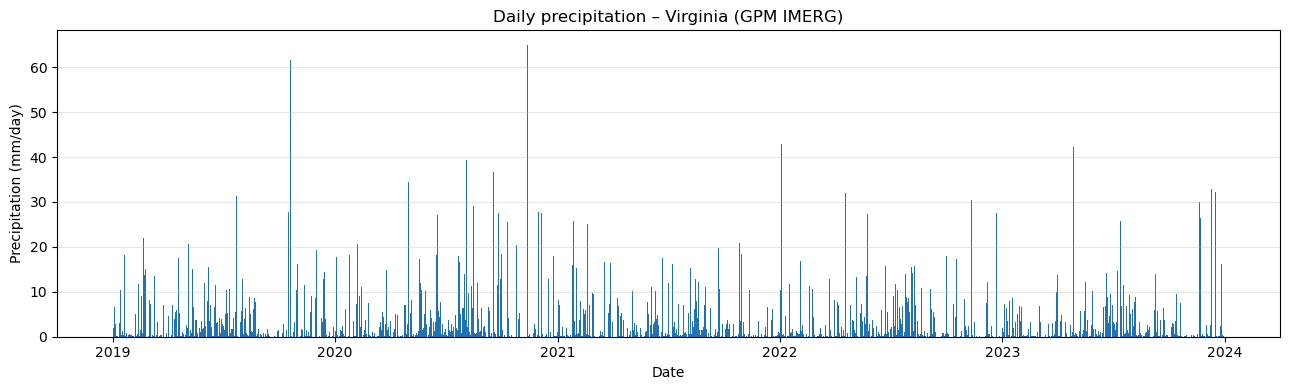

In [6]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(s.index, s.values, width=1.0, color="#2171b5")
ax.set(xlabel="Date", ylabel="Precipitation (mm/day)", title=f"Daily precipitation – {ROI_NAME} (GPM IMERG)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_daily_precip.png"); plt.show()

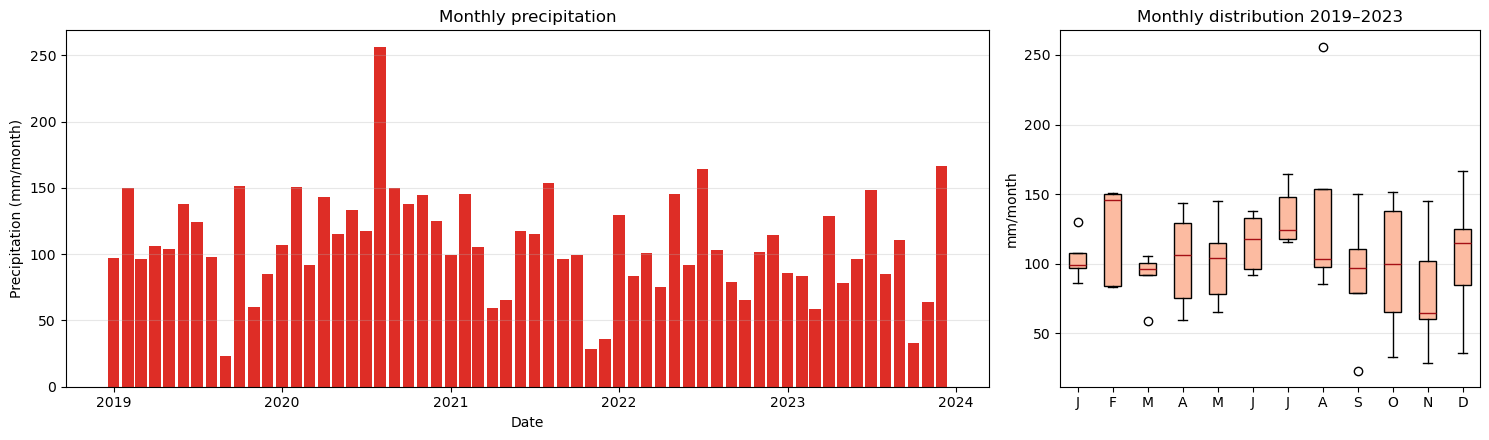

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax1.bar(monthly.index, monthly.values, width=25, color="#de2d26")      # red, as in the original chart
ax1.set(xlabel="Date", ylabel="Precipitation (mm/month)", title="Monthly precipitation")
ax1.grid(axis="y", alpha=0.3)

data = [monthly[monthly.index.month == m].values for m in range(1, 13)]
ax2.boxplot(data, patch_artist=True, boxprops=dict(facecolor="#fcbba1"), medianprops=dict(color="#a50f15"))
ax2.set_xticks(range(1, 13)); ax2.set_xticklabels(list("JFMAMJJASOND"))
ax2.set(ylabel="mm/month", title=f"Monthly distribution {START_YEAR}–{END_YEAR}")
ax2.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_monthly_precip.png"); plt.show()

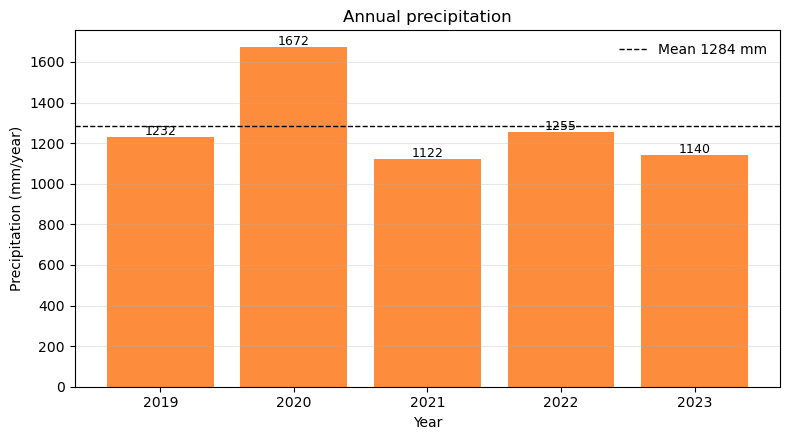

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(annual.index.astype(str), annual.values, color="#fd8d3c")   # orange, as in the original chart
ax.axhline(annual.mean(), color="k", ls="--", lw=1, label=f"Mean {annual.mean():.0f} mm")
for bar, v in zip(bars, annual.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 10, f"{v:.0f}", ha="center", fontsize=9)
ax.set(xlabel="Year", ylabel="Precipitation (mm/year)", title="Annual precipitation")
ax.legend(frameon=False); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_annual_precip.png"); plt.show()

## 6. Annual precipitation maps and GeoTIFF export

Each year's total is computed per pixel at the native 0.1° grid. The values are downloaded as arrays for plotting
and, if `DOWNLOAD_GEOTIFF = True`, as GeoTIFF files in `outputs/gpm/` (this replaces `Export.image.toDrive`,
so no Google Drive is needed). Each year is saved before the next one is requested.

2019: done
2020: done
2021: done
2022: done
2023: done


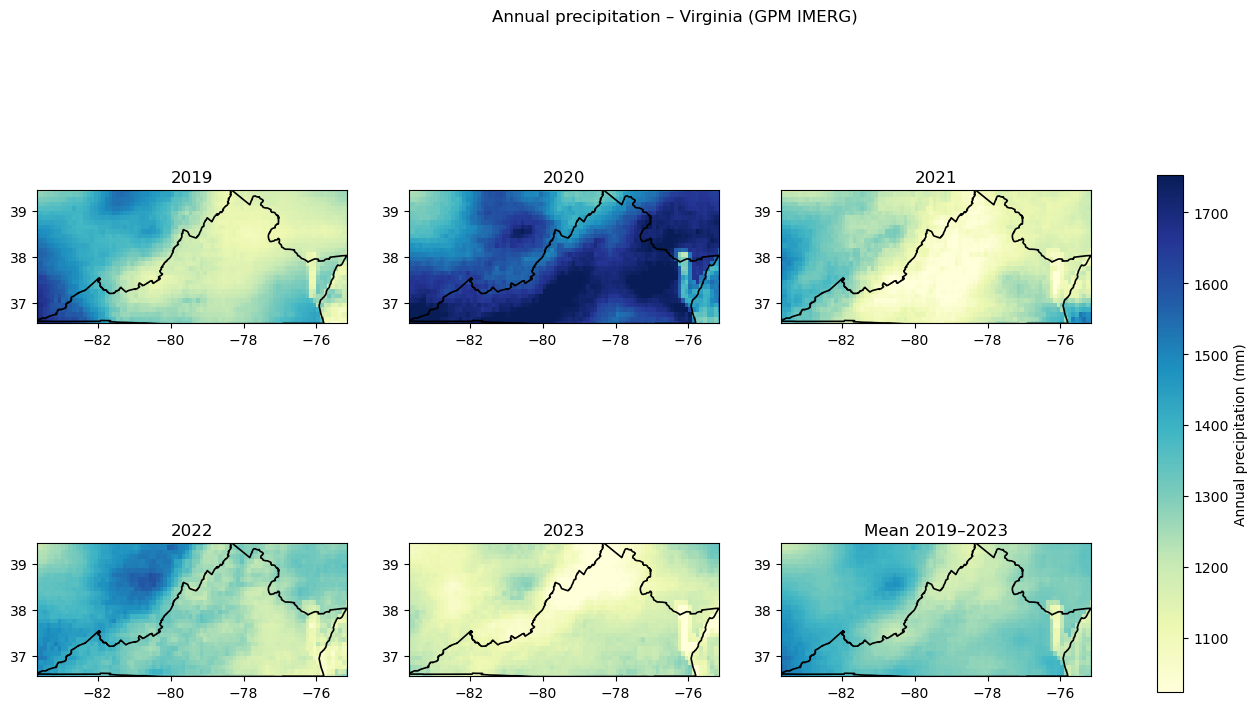

In [9]:
def annual_image(year):
    return (gpm.filterDate(f"{year}-01-01", f"{year + 1}-01-01").sum()
               .multiply(HOURS_PER_IMAGE).rename("precip_mm").float())

grids = {}
for year in range(START_YEAR, END_YEAR + 1):
    npz = f"{OUT_DIR}/annual_grid_{year}.npz"
    if os.path.exists(npz) and not FORCE_RECOMPUTE:
        grids[year] = dict(np.load(npz))
        continue
    img = annual_image(year)
    stack = img.addBands(ee.Image.pixelLonLat()).reproject(crs="EPSG:4326", crsTransform=CRS_TRANSFORM)
    props = stack.sampleRectangle(region=roi.bounds(), defaultValue=-9999).getInfo()["properties"]
    grid = {k: np.array(props[k], dtype=float) for k in ["precip_mm", "longitude", "latitude"]}
    np.savez(npz, **grid)
    grids[year] = grid
    if DOWNLOAD_GEOTIFF:
        url = img.clip(roi).getDownloadURL({"name": f"gpm_precip_{year}", "scale": SCALE, "region": roi.bounds(),
                                            "crs": "EPSG:4326", "format": "GEO_TIFF"})
        with open(f"{OUT_DIR}/gpm_precip_{year}.tif", "wb") as fh:
            fh.write(requests.get(url, timeout=600).content)
    print(f"{year}: done")

def draw_outline(ax, g, **kw):
    if g["type"] == "Polygon":
        ring = np.array(g["coordinates"][0]); ax.plot(ring[:, 0], ring[:, 1], **kw)
    elif g["type"] == "MultiPolygon":
        for poly in g["coordinates"]:
            ring = np.array(poly[0]); ax.plot(ring[:, 0], ring[:, 1], **kw)
    elif g["type"] == "GeometryCollection":
        for sub in g["geometries"]:
            draw_outline(ax, sub, **kw)

roi_geom = roi.getInfo()
years = sorted(grids)
masked = {y: np.ma.masked_less(grids[y]["precip_mm"], 0) for y in years}
lon, lat = grids[years[0]]["longitude"], grids[years[0]]["latitude"]
mean_map = np.ma.mean(np.ma.stack([masked[y] for y in years]), axis=0)
vmin, vmax = np.percentile(np.concatenate([m.compressed() for m in masked.values()]), [2, 98])

panels = [(masked[y], str(y)) for y in years] + [(mean_map, f"Mean {years[0]}–{years[-1]}")]
ncol = 3
nrow = int(np.ceil(len(panels) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(17, 4.2 * nrow))
for ax, (data, title) in zip(np.ravel(axes), panels):
    pm = ax.pcolormesh(lon, lat, data, cmap="YlGnBu", vmin=vmin, vmax=vmax, shading="nearest")
    draw_outline(ax, roi_geom, color="black", lw=1.2)
    ax.set_title(title); ax.set_aspect(1 / np.cos(np.deg2rad(37.5)))
    ax.set_xlim(lon.min(), lon.max()); ax.set_ylim(lat.min(), lat.max())
for ax in np.ravel(axes)[len(panels):]:
    ax.axis("off")
fig.colorbar(pm, ax=axes, label="Annual precipitation (mm)", shrink=0.8)
fig.suptitle(f"Annual precipitation – {ROI_NAME} (GPM IMERG)", y=1.0)
fig.savefig(f"{FIG_DIR}/04_annual_maps.png", bbox_inches="tight"); plt.show()

## 7. Notes

- **Data:** Huffman et al., *GPM IMERG Final Precipitation L3 Half Hourly 0.1° × 0.1° V07*, NASA GES DISC.
- IMERG's `precipitation` band is a rate (mm/hr). Totals are the sum of half-hourly rates × 0.5 h; summing the raw
  half-hourly values (as in the original script) would double the totals.
- In the original script the collection was filtered to 2021 only while 1825 days, 60 months and 5 years were requested,
  so all periods after 2021 were empty. Here the period is set by `START_YEAR` and `N_YEARS`.
- If your original `imageCollection` import was a different GPM product (for example the monthly IMERG collection),
  change `GPM_COLLECTION` and `HOURS_PER_IMAGE` accordingly.
- Regional values are area means over Virginia; the GeoTIFFs cover the state's bounding box and are clipped to the state.